In [1]:
import sys
!{sys.executable} -m pip install matplotlib seaborn pandas numpy scikit-learn joblib



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

# Apni CSV file ka naam
CSV_PATH = "sales_data.csv"

# Apni CSV ke exact column names yahan likho
DATE_COL = "Date"
TARGET_COL = "Units Sold"

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
print(df.info())


Dataset shape: (76000, 16)
Columns: ['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand']


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  str    
 1   Store ID            76000 non-null  str    
 2   Product ID          76000 non-null  str    
 3   Category            76000 non-null  str    
 4   Region              76000 non-null  str    
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  str    
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  str    
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: float64(2), 

In [3]:

# Sirf required columns use karo
data = df[[DATE_COL, TARGET_COL]].copy()

data[DATE_COL] = pd.to_datetime(data[DATE_COL], errors="coerce")
data[TARGET_COL] = pd.to_numeric(data[TARGET_COL], errors="coerce")

data = data.dropna(subset=[DATE_COL, TARGET_COL])
data = data[data[TARGET_COL] >= 0]

# Daily total sales
daily = (
    data.groupby(DATE_COL)[TARGET_COL]
    .sum()
    .sort_index()
    .to_frame("sales")
)

# Missing calendar dates ko include karo
full_dates = pd.date_range(
    start=daily.index.min(),
    end=daily.index.max(),
    freq="D"
)

daily = daily.reindex(full_dates)
daily.index.name = "date"

# Missing dates par sales zero assume kar rahe hain.
# Agar missing date ka matlab missing record hai, zero fill karne se pehle data check karo.
daily["sales"] = daily["sales"].fillna(0)

print("Daily records:", len(daily))
print("Date range:", daily.index.min(), "to", daily.index.max())
display(daily.head())


Daily records: 760
Date range: 2022-01-01 00:00:00 to 2024-01-30 00:00:00


,sales
date,
2022-01-01,8601
2022-01-02,7684
2022-01-03,5965
2022-01-04,7859
2022-01-05,9621


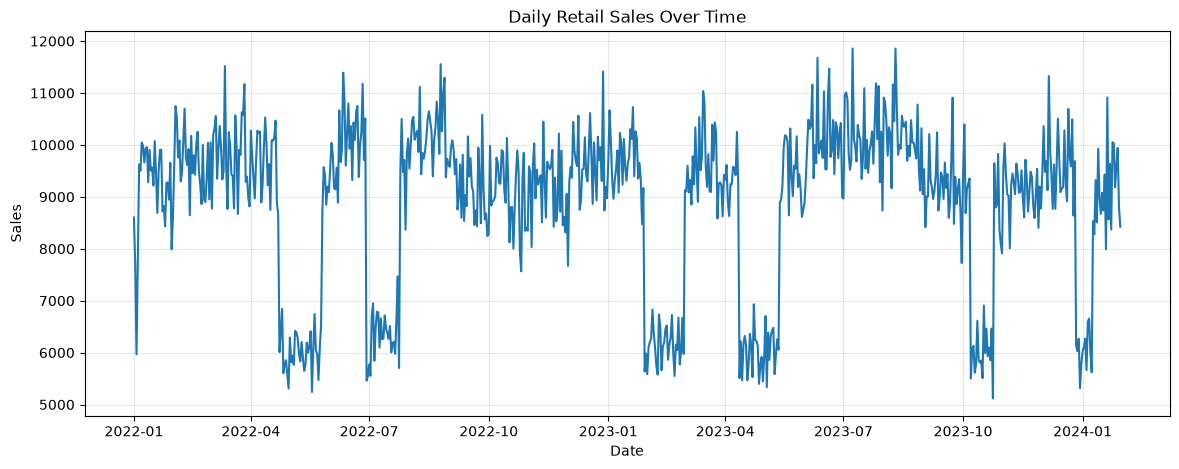

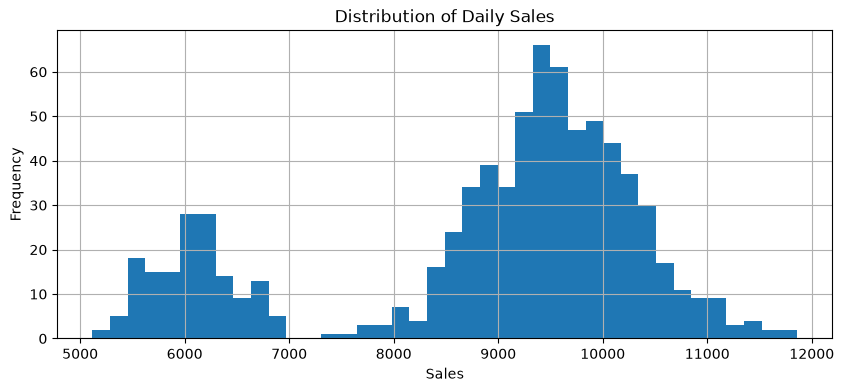

count      760.000000
mean      8882.731579
std       1558.655953
min       5117.000000
25%       8524.000000
50%       9351.500000
75%       9926.500000
max      11858.000000
Name: sales, dtype: float64
Missing values:
 sales    0
dtype: int64


In [4]:

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily["sales"])
plt.title("Daily Retail Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
daily["sales"].hist(bins=40)
plt.title("Distribution of Daily Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

print(daily["sales"].describe())
print("Missing values:\n", daily.isnull().sum())


In [5]:

def make_features(series):
    X = pd.DataFrame(index=series.index)

    X["day_of_week"] = series.index.dayofweek
    X["day_of_month"] = series.index.day
    X["month"] = series.index.month
    X["quarter"] = series.index.quarter
    X["day_of_year"] = series.index.dayofyear
    X["is_weekend"] = (series.index.dayofweek >= 5).astype(int)

    for lag in [1, 7, 14, 28]:
        X[f"lag_{lag}"] = series.shift(lag)

    X["rolling_mean_7"] = series.shift(1).rolling(7).mean()
    X["rolling_mean_28"] = series.shift(1).rolling(28).mean()
    X["rolling_std_7"] = series.shift(1).rolling(7).std()

    return X

features = make_features(daily["sales"])

model_data = features.copy()
model_data["sales"] = daily["sales"]
model_data = model_data.replace([np.inf, -np.inf], np.nan).dropna()

X = model_data.drop(columns="sales")
y = model_data["sales"]

print("Feature shape:", X.shape)
display(model_data.head())


Feature shape: (732, 13)


,day_of_week,day_of_month,month,quarter,day_of_year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_7,sales
date,,,,,,,,,,,,,,
2022-01-29,5,29,1,1,29,1,8945.0,9908.0,9566.0,8601.0,9053.857143,9187.714286,480.742977,9655
2022-01-30,6,30,1,1,30,1,9655.0,8721.0,9218.0,7684.0,9017.714286,9225.357143,410.152701,7992
2022-01-31,0,31,1,1,31,0,7992.0,8822.0,10074.0,5965.0,8913.571429,9236.357143,562.358384,8592
2022-02-01,1,1,2,1,32,0,8592.0,8434.0,9444.0,7859.0,8880.714286,9330.178571,575.173514,9599
2022-02-02,2,2,2,1,33,0,9599.0,9271.0,8689.0,9621.0,9047.142857,9392.321429,592.654882,10746


In [6]:

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

split_idx = int(len(model_data) * 0.80)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Test starts:", X_test.index.min())

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = np.maximum(model.predict(X_test), 0)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best model:", best_name)


Training rows: 585
Testing rows: 147
Test starts: 2023-09-06 00:00:00


,Model,MAE,RMSE
1,Extra Trees,636.018646,880.779283
0,Random Forest,652.171339,903.858214


Best model: Extra Trees


,Actual Sales,Predicted Sales
date,,
2023-09-06,9316,9288.504099
2023-09-07,9192,9335.012572
2023-09-08,8960,9261.589932
2023-09-09,9126,9484.236934
2023-09-10,9407,9500.281960
2023-09-11,10243,9205.865567
2023-09-12,8738,9070.056003
2023-09-13,8985,9237.628861
2023-09-14,9470,9205.823553


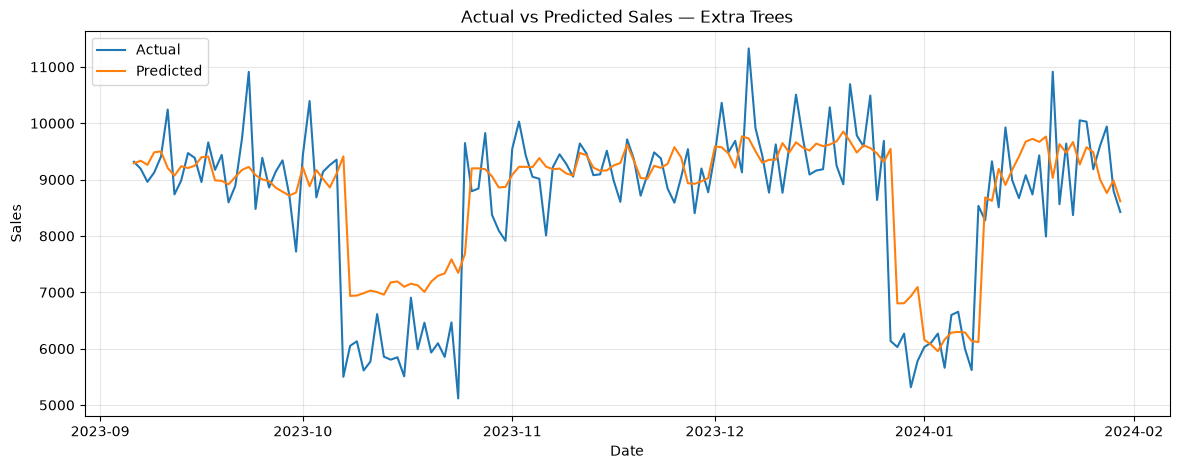

MAE: 636.02
RMSE: 880.78


In [7]:

test_predictions = np.maximum(best_model.predict(X_test), 0)

comparison = pd.DataFrame({
    "Actual Sales": y_test,
    "Predicted Sales": test_predictions
}, index=y_test.index)

display(comparison.head(15))

plt.figure(figsize=(14, 5))
plt.plot(comparison.index, comparison["Actual Sales"], label="Actual")
plt.plot(comparison.index, comparison["Predicted Sales"], label="Predicted")
plt.title(f"Actual vs Predicted Sales — {best_name}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")


,date,forecast_sales
0,2024-01-31,8732.552222
1,2024-02-01,9791.093203
2,2024-02-02,10046.428794
3,2024-02-03,9988.905433
4,2024-02-04,9737.942392
5,2024-02-05,9726.432359
6,2024-02-06,9762.624954
7,2024-02-07,9793.323870
8,2024-02-08,9694.902711
9,2024-02-09,9915.435678


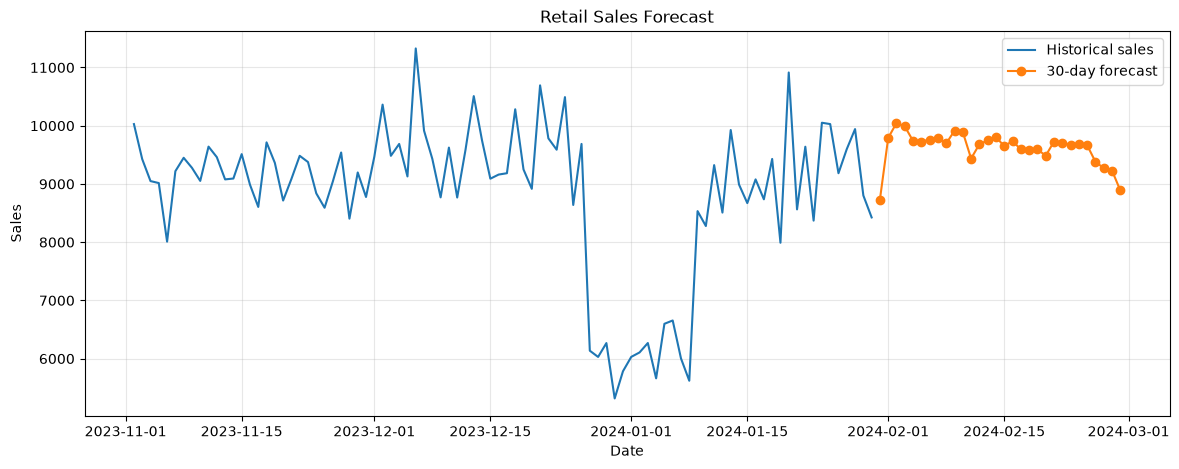

In [8]:

forecast_days = 30

history = daily["sales"].copy()
future_dates = pd.date_range(
    start=history.index.max() + pd.Timedelta(days=1),
    periods=forecast_days,
    freq="D"
)

future_predictions = []

for future_date in future_dates:
    temp_series = pd.concat([
        history,
        pd.Series([np.nan], index=[future_date])
    ])

    feature_row = make_features(temp_series).iloc[[-1]]
    feature_row = feature_row.reindex(columns=X.columns)

    prediction = max(float(best_model.predict(feature_row)[0]), 0)
    future_predictions.append(prediction)

    history.loc[future_date] = prediction

forecast_df = pd.DataFrame({
    "date": future_dates,
    "forecast_sales": future_predictions
})

display(forecast_df)

plt.figure(figsize=(14, 5))
plt.plot(daily.index[-90:], daily["sales"].iloc[-90:], label="Historical sales")
plt.plot(forecast_df["date"], forecast_df["forecast_sales"],
         label="30-day forecast", marker="o")
plt.title("Retail Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [9]:

os.makedirs("project2_outputs", exist_ok=True)

results_df.to_csv("project2_outputs/model_comparison.csv", index=False)
comparison.to_csv("project2_outputs/test_predictions.csv")
forecast_df.to_csv("project2_outputs/next_30_days_forecast.csv", index=False)

joblib.dump(
    {
        "model": best_model,
        "feature_columns": X.columns.tolist(),
        "model_name": best_name
    },
    "project2_outputs/demand_forecasting_model.joblib"
)

print("Project 2 complete!")
print("Files saved in project2_outputs/")


Project 2 complete!
Files saved in project2_outputs/
